- ## Data Acquisition for climate change in Reddit

- Reddit is a social news forum where registered users post their content like texts, images, videos and links which are then voted up or down by other members in the subreddits.
- These are user-created boards for discussion.
- We acquired 9948 top posts and top comments and their details from PRAW(Python Reddit API Wrapper) that interacts with Reddit’s API seamlessly from 10 different climate change related discussion groups.


To use the PRAW libary.
- 1. Create a [reddit account](https://www.reddit.com/register/)

- 2. Go to your app preferences. [reddit app](https://www.reddit.com/prefs/apps) and create a app as in the screenshot. choose name of the app and fill the details.
  
    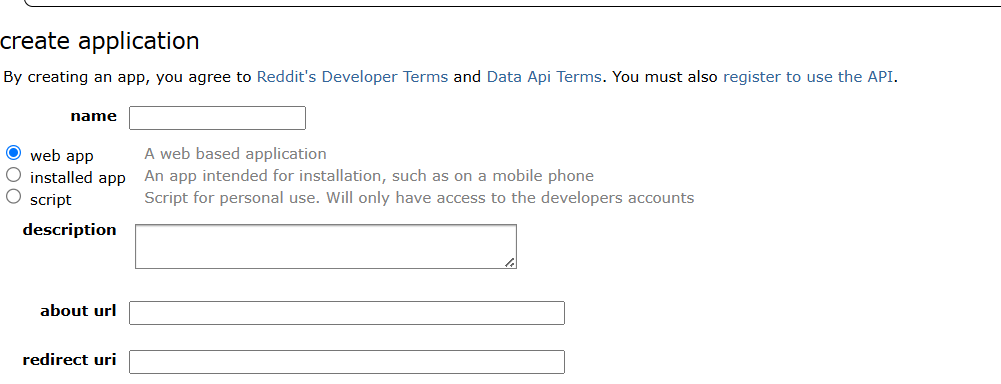



- 3. Get your client_id and client_secret from your app.And secure it.

    ![Screenshot 2025-06-20 162225.png](<attachment:Screenshot 2025-06-20 162225.png>)


- Install the python packge `PRAW` `pip install praw`
- Load CLIENT_ID and CLIENT_SECRET as variables in .env files.
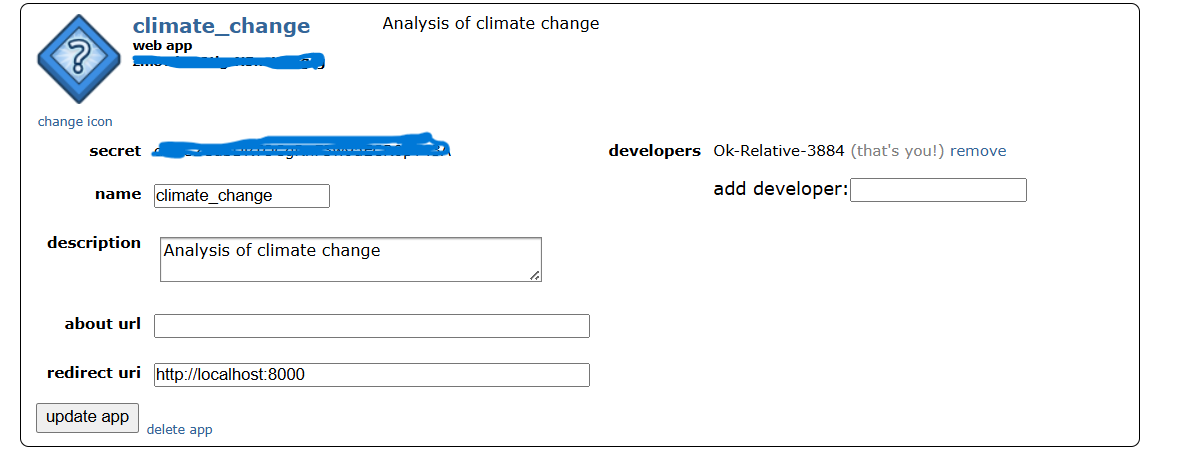

### Loading the necessary libraries.

In [15]:
import praw
import pandas as pd
import numpy as np
from dotenv import load_dotenv 
import os
import time
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor
from prawcore.exceptions import RequestException, ResponseException, ServerError
import glob
load_dotenv() 
import matplotlib.pyplot as plt
import seaborn as sns
import re
from langdetect import detect, LangDetectException

- load the client_id and client_secret from the .env file

In [2]:
reddit = praw.Reddit(
    client_id=os.getenv('CLIENT_ID'),
    client_secret=os.getenv('CLIENT_SECRET'),
    user_agent=os.getenv('USER_AGENT'))
reddit.read_only

True

- I acquired top 1000 post  data from these subredits: "climatechange", "environment", "climateskeptics", "climate",
    "sustainability", "EcoInternet", "Collapse", "energy",
    "renewableenergy", "ZeroWaste"

In [3]:
subreddits = [
    "climatechange", "environment", "climateskeptics", "climate",
    "sustainability", "EcoInternet", "Collapse", "energy",
    "renewableenergy", "ZeroWaste"
]


- We retrieve top posts(subreddit.top) to get the best posts over time which is the most upvotes(score) within a specified time_filter

In [ ]:

# Function to fetch posts and top-level comments
def fetch_posts(subreddit_name, limit=1000):
    posts_data = []
    subreddit = reddit.subreddit(subreddit_name)
    print(f"Fetching from r/{subreddit_name}...")

    try:
        for index, post in enumerate(subreddit.top(limit=limit)):
            # Safely get top comment
            post.comments.replace_more(limit=0)
            top_comment = post.comments[0] if post.comments else None

            posts_data.append({
                "subreddit": subreddit_name,
                "id": post.id,
                "title": post.title,
                "selftext": post.selftext,
                "score": post.score,
                "num_comments": post.num_comments,
                "created_utc": post.created_utc,
                "author": str(post.author),
                "url": post.url,
                "top_comment": top_comment.body if top_comment else None,
                "top_comment_author": str(top_comment.author) if top_comment else None,
                "top_comment_score": top_comment.score if top_comment else None
            })

            if index % 100 == 0:
                print(f"  Retrieved {index} posts from r/{subreddit_name}")
            time.sleep(0.2)  

    except (RequestException, ResponseException, ServerError) as e:
        print(f"Error fetching r/{subreddit_name}: {e}")

    return posts_data


# Main loop to fetch and save data per subreddit
for sr in subreddits:
    data = fetch_posts(sr)
    if data:
        df = pd.DataFrame(data)
        df.to_csv(f"{sr}_posts.csv", index=False)
        print(f"✅ Saved {len(df)} posts from r/{sr} to {sr}_posts.csv")
    else:
        print(f"⚠️ No data saved for r/{sr}")


Fetching from r/climatechange...
  Retrieved 0 posts from r/climatechange
  Retrieved 100 posts from r/climatechange
  Retrieved 200 posts from r/climatechange
  Retrieved 300 posts from r/climatechange
  Retrieved 400 posts from r/climatechange
  Retrieved 500 posts from r/climatechange
  Retrieved 600 posts from r/climatechange
  Retrieved 700 posts from r/climatechange
  Retrieved 800 posts from r/climatechange
  Retrieved 900 posts from r/climatechange
✅ Saved 999 posts from r/climatechange to climatechange_posts.csv
Fetching from r/environment...
  Retrieved 0 posts from r/environment
  Retrieved 100 posts from r/environment
  Retrieved 200 posts from r/environment
  Retrieved 300 posts from r/environment
  Retrieved 400 posts from r/environment
  Retrieved 500 posts from r/environment
  Retrieved 600 posts from r/environment
  Retrieved 700 posts from r/environment
  Retrieved 800 posts from r/environment
  Retrieved 900 posts from r/environment
✅ Saved 966 posts from r/environme

: 

#### - This took me more than 350 minutes to run.The API or either my computer stop working,so i resumed the work avoiding to download posts already downloaded.

In [11]:
subreddits = [
    "climatechange", "environment", "climateskeptics", "climate",
    "sustainability", "EcoInternet", "Collapse", "energy",
    "renewableenergy", "ZeroWaste"
]

def fetch_posts(subreddit_name, limit=1000):  
    
    posts_data = []
    subreddit = reddit.subreddit(subreddit_name)
    print(f"▶ Fetching from r/{subreddit_name}...")

    try:
        for index, post in enumerate(subreddit.top(limit=limit)):
            post.comments.replace_more(limit=0)
            top_comment = post.comments[0] if post.comments else None

            posts_data.append({
                "subreddit": subreddit_name,
                "id": post.id,
                "title": post.title,
                "selftext": post.selftext,
                "score": post.score,
                "num_comments": post.num_comments,
                "created_utc": post.created_utc,
                "author": str(post.author),
                "url": post.url,
                "top_comment": top_comment.body if top_comment else None,
                "top_comment_author": str(top_comment.author) if top_comment else None,
                "top_comment_score": top_comment.score if top_comment else None
            })

            if index % 100 == 0:
                print(f"  ✅ Retrieved {index} posts from r/{subreddit_name}")
            time.sleep(0.2)  # Light throttle to avoid bans

    except (RequestException, ResponseException, ServerError) as e:
        print(f"⚠️ Error fetching r/{subreddit_name}: {e}")

    return posts_data


def process_subreddit(subreddit_name):
    output_file = f"{subreddit_name}_posts.csv"
    if os.path.exists(output_file):
        print(f"⏭️ Skipping r/{subreddit_name}, already fetched.")
        return

    data = fetch_posts(subreddit_name)
    if data:
        df = pd.DataFrame(data)
        df.to_csv(output_file, index=False)
        print(f"✅ Saved {len(df)} posts from r/{subreddit_name} to {output_file}")
    else:
        print(f"⚠️ No data saved for r/{subreddit_name}")


# Use a thread pool to speed up scraping
if __name__ == "__main__":
    with ThreadPoolExecutor(max_workers=5) as executor:
        executor.map(process_subreddit, subreddits)

⏭️ Skipping r/climatechange, already fetched.
⏭️ Skipping r/environment, already fetched.
⏭️ Skipping r/climateskeptics, already fetched.
⏭️ Skipping r/climate, already fetched.
⏭️ Skipping r/sustainability, already fetched.
⏭️ Skipping r/EcoInternet, already fetched.
⏭️ Skipping r/energy, already fetched.
⏭️ Skipping r/Collapse, already fetched.
⏭️ Skipping r/renewableenergy, already fetched.
▶ Fetching from r/ZeroWaste...
  ✅ Retrieved 0 posts from r/ZeroWaste
  ✅ Retrieved 100 posts from r/ZeroWaste
  ✅ Retrieved 200 posts from r/ZeroWaste
  ✅ Retrieved 300 posts from r/ZeroWaste
  ✅ Retrieved 400 posts from r/ZeroWaste
  ✅ Retrieved 500 posts from r/ZeroWaste
  ✅ Retrieved 600 posts from r/ZeroWaste
  ✅ Retrieved 700 posts from r/ZeroWaste
  ✅ Retrieved 800 posts from r/ZeroWaste
  ✅ Retrieved 900 posts from r/ZeroWaste
✅ Saved 994 posts from r/ZeroWaste to ZeroWaste_posts.csv


- Combining all the datasets for 10 different climate change discussion formus in Reddit to one.

In [ ]:
csv_files = glob.glob("*_posts.csv")
combined_df = pd.concat([pd.read_csv(file) for file in csv_files], ignore_index=True)

combined_df.to_csv("climatechange_combined.csv", index=False)

print(f"Combined {len(csv_files)} files into 'climatechange_combined.csv'")


✅ Combined 10 files into 'climatechange_combined.csv'


- ## Data Engineering

- We read the combined dataset from all the 10 climate change related disussion forums in Reddit that we acquired via API.

In [16]:
df = pd.read_csv("climatechange_combined.csv")

- looking at the sample of the dataset

In [17]:
df.sample(3)

,subreddit,id,title,selftext,score,num_comments,created_utc,author,url,top_comment,top_comment_author,top_comment_score
6206,environment,5fj21x,Outdoor clothing company Patagonia donates ent...,NaN,6486,175,1.480432e+09,DonManuel,http://www.independent.co.uk/news/business/new...,"smart move. good pr, and theres no point havin...",ss0889,456.0
2892,climate,1185mvz,"Jimmy Carter, the president who tried to save ...",NaN,963,31,1.676992e+09,silence7,https://www.washingtonpost.com/climate-environ...,He started to deal with global warming and Rea...,bananafor,51.0
9826,ZeroWaste,vgp64r,Never buy green onions again,NaN,2571,97,1.655742e+09,Sassmaster008,https://i.redd.it/wy3jr063wh691.jpg,But the best part is at the bottom near the ro...,chickfromthejungle,161.0


- ### Here the columns have meaning similar to their names and can be described as:
- subreddit - the subreddit disussion forum from which we got the reddit posts
- id - user id who posted it
- title - headline of the post
- self-text - body of the post
- score - net upvotes(upvotes minus downvotes)
- num_comments - total number of comments
- created_utc - The created_utc is the number of seconds since Janurary 1,1970(00:00:00UTC);we will convert this date to understandable form.
- author- Reddit username of post creator
- url - Url the posts link to
- top_comment - the text of highest-scoring comment
- top_comment_author - author of top_comment
- top_comment_score - the score of top_comment.

- Looking for duplicated rows id any.

In [18]:
print("The number of duplicated rows:", df.duplicated().sum())

The number of duplicated rows: 0


- Looking for null values.

In [19]:
df.isnull().sum()

subreddit                0
id                       0
title                    0
selftext              9273
score                    0
num_comments             0
created_utc              0
author                1710
url                      0
top_comment            842
top_comment_author    2170
top_comment_score      841
dtype: int64

- We have zero null values for title,score and num_comments which is good for our analysis.
- Then we combine title and self text as a single text.

-  Since most of the posts lack self text beacuse they are link posts

In [20]:
df['post_type'] = df['url'].apply(lambda x: 'self_post' if 'reddit.com/r/' in str(x) and '/comments/' in str(x) else 'link_post')
post_types = df['post_type'].value_counts()
post_types


post_type
link_post    9445
self_post     503
Name: count, dtype: int64

Text(0.5, 0, 'Post Type')

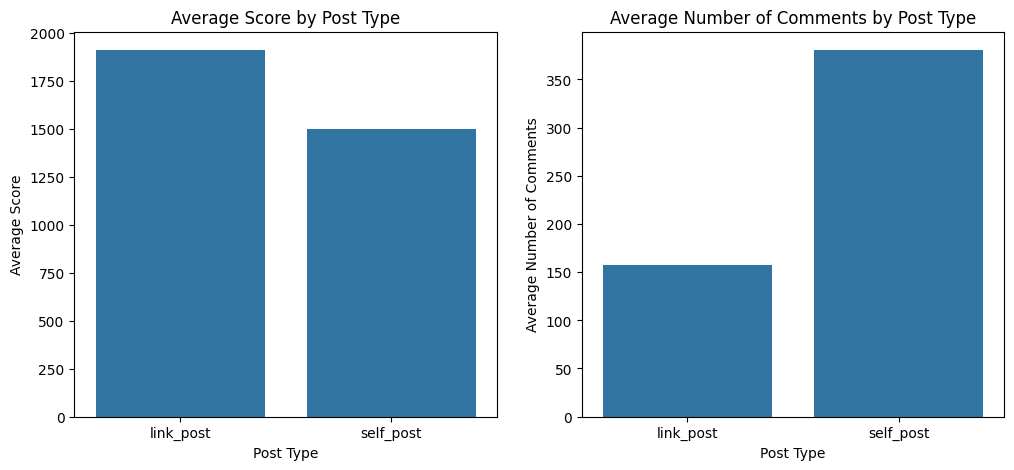

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(x='post_type', y='score', data=df, estimator=np.mean, errorbar=None, ax=axes[0])
axes[0].set_title('Average Score by Post Type')
axes[0].set_ylabel('Average Score')
axes[0].set_xlabel('Post Type')

sns.barplot(x='post_type', y='num_comments', data=df, estimator=np.mean, errorbar=None, ax=axes[1])
axes[1].set_title('Average Number of Comments by Post Type')
axes[1].set_ylabel('Average Number of Comments')
axes[1].set_xlabel('Post Type')


 - We higher mean score for link_post than self_post and higher mean number of comments for self post.We will take this in consideration while developing the enagegment score.

- The created_utc is the number of seconds since Janurary 1,1970(00:00:00UTC);we will convert this date to understandable form.

In [22]:
df["Date"] = pd.to_datetime(df["created_utc"], unit="s")
df = df.set_index("Date")

- From the above dataset,we should omit id,author,top_comment_author from the dataset since Reddit wants anoyomity of users for any Research usage of its dataset.
- Then we combine title and self text(although it has very less non-null values) as a single text.


- I first tried to analyse text and comment seprately,but rather than text vs reaction . I wanted to get the sentiment of general discussions of the reddit posts so,i combined the comment to the text.
- And comment are mostly related to text.It gives us overall text.

In [23]:
df["text"] = df["title"] + " " + df["selftext"].fillna("") + " " + df["top_comment"].fillna("")

- I don't see any releveance of URL in sentiment analysis,so we also remove Url from the dataframe.

In [24]:
df = df.drop(columns=["title", "selftext","id", "created_utc", "author", "top_comment_author","url", "top_comment"])

In [25]:
df.head()

,subreddit,score,num_comments,top_comment_score,post_type,text
Date,,,,,,
2025-01-13 21:55:09,climatechange,7173,1034,988.0,link_post,We’ve Crossed a Key Threshold for Climate Chan...
2024-12-23 11:51:10,climatechange,5869,271,182.0,link_post,Venezuela is the first country to lose all of ...
2024-10-18 18:01:14,climatechange,4483,82,76.0,link_post,Harris win would be a 'big relief' for climate...
2023-10-20 00:58:25,climatechange,4470,738,401.0,link_post,Billions of crabs went missing around Alaska. ...
2024-10-07 17:10:29,climatechange,4451,618,360.0,link_post,We’re Not Prepared for What Hurricane Milton M...


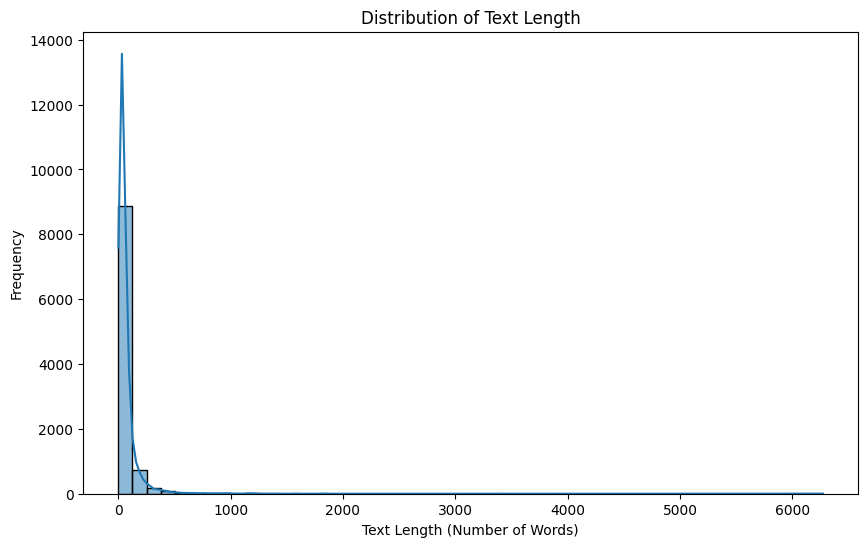

In [26]:
df['text_length'] = df['text'].apply(lambda x: len(str(x).split()))
plt.figure(figsize=(10, 6))
sns.histplot(df['text_length'], bins=50, kde=True)
plt.title('Distribution of Text Length')
plt.xlabel('Text Length (Number of Words)')
plt.ylabel('Frequency')
plt.show()

In [27]:
df['text_length'].describe()

count    9948.000000
mean       68.496884
std       124.597433
min         2.000000
25%        22.000000
50%        41.000000
75%        73.000000
max      6271.000000
Name: text_length, dtype: float64

- Average text_legth is 68.5


- We can assign  <b>score</b> as Popularity metric(High score meaning Higher popularity of the text).
- <b>num_comments</b> can be defined as Discussion-driven metric(Lots of comments meaning higher discussion)
- <b>top_comment_score</b> can be defined as depth-driven metric.
-  Score is important for popularity, but not dominant.
-  Number of comments is much higher for self_post, indicating more discussion, so higher weight.
- I want to derive a enagement metric based on these features.
- I assign weight = 1 for score, weight = 3 for num_comments and weight = 2 for top_comment_score and take a logarithmic of the total

In [28]:
mean_stats = df.groupby('post_type')[['score', 'num_comments']].mean()
print(mean_stats)

                 score  num_comments
post_type                           
link_post  1911.119746    157.433351
self_post  1497.369781    380.654076


In [29]:
df['top_comment_score'] = df['top_comment_score'].fillna(df['top_comment_score'].mean())

In [30]:
weight_post_score = 1
weight_num_comments = 3
weight_top_comment = 2

df['engagement_score'] = np.log1p(
    weight_post_score * df['score'] +
    weight_num_comments * df['num_comments'] +
    weight_top_comment * df['top_comment_score']
)


In [31]:
# Drop unwanted columns from df if they still exist
columns_to_drop = ["score", "num_comments","post_type","top_comment_score"]
df = df.drop(columns=[col for col in columns_to_drop if col in df.columns])
df.sample(5)

,subreddit,text,text_length,engagement_score
Date,,,,
2021-03-21 17:43:12,Collapse,Elon Musk is One of the Biggest Charlatans of ...,230,8.698681
2021-02-14 03:52:16,sustainability,Vibrating wind turbine Wacky waving arm flail...,10,7.104965
2022-01-21 22:53:12,environment,Beef Production is Killing the Amazon Rainfore...,71,8.776939
2024-08-23 02:18:29,climate,Joe Rogan continues to cast doubt on climate s...,71,7.421776
2022-11-08 14:07:15,renewableenergy,Solar and wind each added more capacity in US ...,161,5.811141


In [32]:
df.isnull().sum()

subreddit           0
text                0
text_length         0
engagement_score    0
dtype: int64

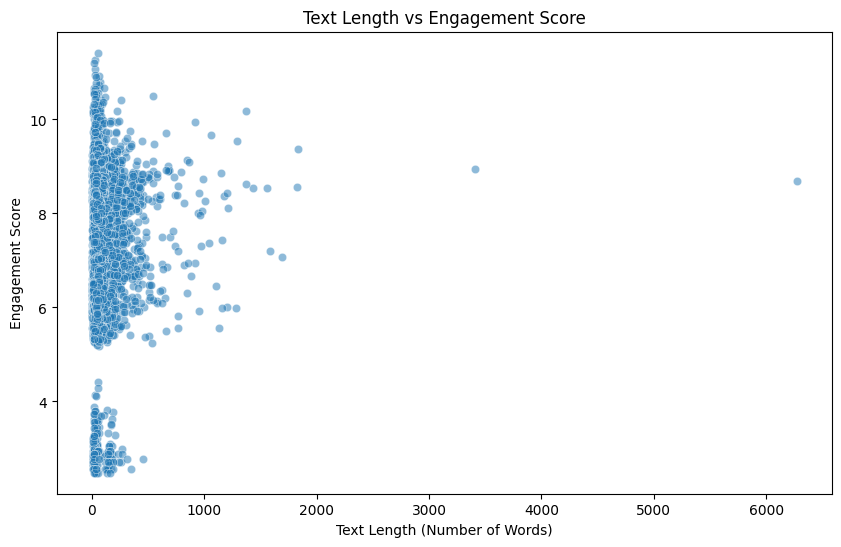

In [33]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='text_length', y='engagement_score', data=df, alpha=0.5)
plt.title('Text Length vs Engagement Score')
plt.xlabel('Text Length (Number of Words)')
plt.ylabel('Engagement Score')
plt.show()

- checking the details of dataframe.

In [34]:
df.describe()

,text_length,engagement_score
count,9948.000000,9948.000000
mean,68.496884,7.198286
std,124.597433,1.287141
min,2.000000,2.484907
25%,22.000000,6.126869
50%,41.000000,7.105786
75%,73.000000,8.309000
max,6271.000000,11.419186


In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 9948 entries, 2025-01-13 21:55:09 to 2021-06-15 12:42:38
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   subreddit         9948 non-null   object 
 1   text              9948 non-null   object 
 2   text_length       9948 non-null   int64  
 3   engagement_score  9948 non-null   float64
dtypes: float64(1), int64(1), object(2)
memory usage: 388.6+ KB


In [36]:
earliest_date = df.index.min()
latest_date = df.index.max()
print("Earliest date:", earliest_date)
print("Latest date:", latest_date)

Earliest date: 2012-06-26 16:02:13
Latest date: 2025-06-08 02:56:01


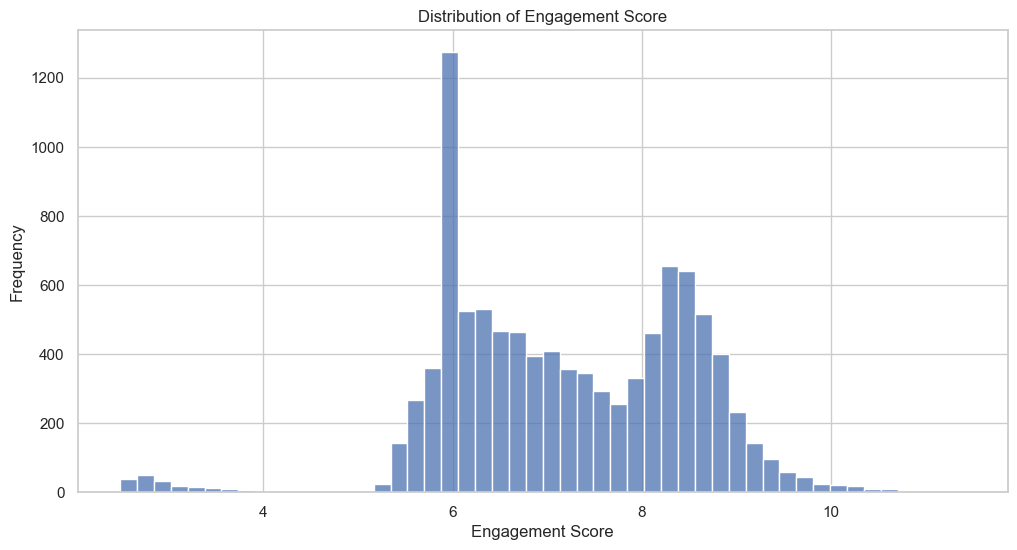

In [37]:
#Looking at the distribution of engagement scores
plt.figure(figsize=(12, 6))
sns.set(style="whitegrid")
sns.histplot(df['engagement_score'].dropna(), bins=50)
plt.title("Distribution of Engagement Score")
plt.xlabel("Engagement Score")
plt.ylabel("Frequency")
plt.show()

- We see a multimodal distibution of enegaement score.We can segment the data into low engagement(score<4),medium engagement(4-7.8) and high enagagement (score>7.8) groups .
- I will consider this later in sentiment analysis.

- Since most of the text contains URL that aren't vital for sentiment analysis,so we remove URLs from the text

In [38]:
#To delete the Url we used Regex
def clean_text(text):
    if pd.isnull(text):
        return ""
    text = re.sub(r"http\S+", "", text)  
    return text

df["text"] = df["text"].apply(clean_text)



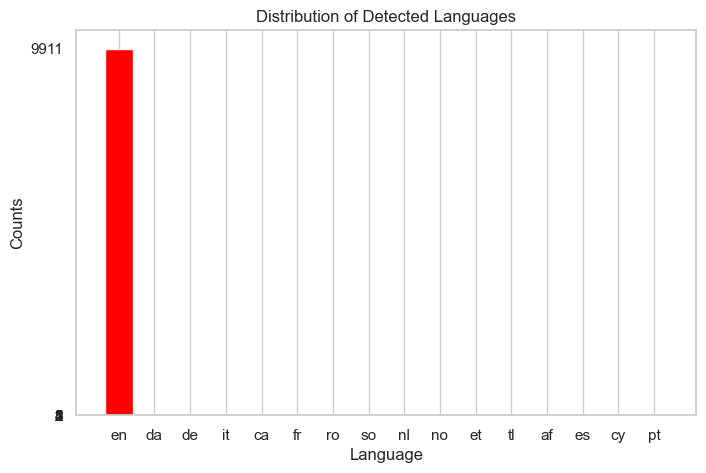

In [39]:
# Do we have langauages othe than English?
def safe_detect(text):
    try:
        return detect(str(text))
    except LangDetectException:
        return "unknown"

df["language"] = df["text"].apply(safe_detect)

language_counts = df["language"].value_counts()
plt.figure(figsize=(8, 5))
plt.bar(language_counts.index, language_counts.values, color="red")
plt.xlabel("Language")
plt.ylabel("Counts")
plt.xticks(language_counts.index)
plt.yticks(language_counts.values)
plt.title("Distribution of Detected Languages")
plt.grid(axis='y')
plt.show()

- All the text is english which is good for our analysis.

In [40]:
df = df.drop(columns=["language"])

In [42]:
df.to_csv("final.csv", index=True)	